# K-means: segmentación del catálogo de Netflix
**Proyecto:** Análisis del catálogo de Netflix y la valoración de usuarios · UNIMINUTO Ibagué

**Pregunta:** ¿Qué tipos de títulos hay en el catálogo y se valoran distinto? K-means es **no supervisado**: no usa la valoración para armar los grupos; solo agrupa títulos parecidos por tipo, duración, año, clasificación y género. Después se mira cuánto valoran los usuarios cada grupo.

**Datos:** los 8.807 títulos del catálogo (ya limpios) con 18 variables. Como K-means mide distancias, las variables se **escalan con `StandardScaler`** (aquí el escalamiento sí se aplica de verdad).

In [1]:
import sys; sys.path.insert(0, '..')
import pandas as pd, numpy as np, matplotlib.pyplot as plt
from scipy import stats
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import silhouette_score
pd.set_option('display.width', 220); pd.set_option('display.max_columns', 20)
from src.lectorDatos import LectorDatos
from src.limpiadorDatos import LimpiadorDatos
from src.modeloKMeans import ModeloKMeans

catalogo = LectorDatos('../CSV/netflix_titles.csv').cargarDatos()
limp = LimpiadorDatos(catalogo); limp.limpiarDatos(); catalogo = limp.corregirYProcesar()
valoraciones = LimpiadorDatos(LectorDatos('../CSV/netflix.csv').cargarDatos()).limpiarDatos()

modelo = ModeloKMeans()
modelo.prepararDatos(catalogo)
print('Títulos:', len(modelo.X), '| Variables:', modelo.variables)

Duplicados eliminados: 0
Duplicados eliminados: 500
Títulos: 8807 | Variables: ['release_year', 'es_serie', 'minutos', 'temporadas', 'infantil', 'adulto', 'g_International Movies', 'g_Dramas', 'g_Comedies', 'g_International TV Shows', 'g_Documentaries', 'g_Action & Adventure', 'g_TV Dramas', 'g_Independent Movies', 'g_Children & Family Movies', 'g_Romantic Movies', 'g_TV Comedies', 'g_Thrillers']


## 1. ¿Por qué K-means y no clustering jerárquico?
Se compararon con el mismo escalado y el mismo silhouette (mayor = grupos más compactos y separados).

k,2,3,4,5,6,7,8,9,10,11,12
K-means,0.226,0.201,0.216,0.237,0.272,0.296,0.290,0.345,0.353,0.357,0.344
Jerárquico (Ward),0.178,0.205,0.213,0.214,0.251,0.270,0.299,0.324,0.323,0.334,0.345


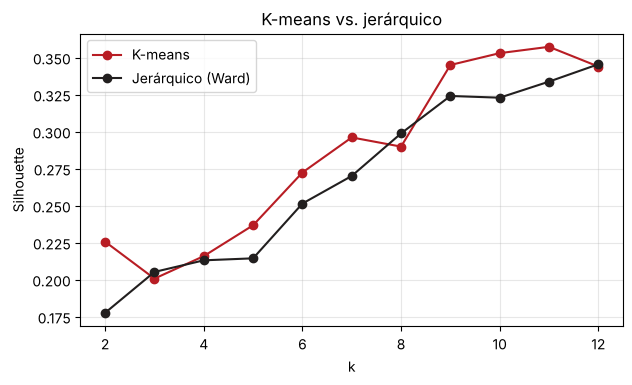

In [2]:
filas = []
for k in range(2, 13):
    lk = KMeans(k, n_init=10, random_state=42).fit_predict(modelo.Xs)
    lw = AgglomerativeClustering(k, linkage='ward').fit_predict(modelo.Xs)
    filas.append({'k': k, 'K-means': silhouette_score(modelo.Xs, lk), 'Jerárquico (Ward)': silhouette_score(modelo.Xs, lw)})
comparacion = pd.DataFrame(filas).set_index('k'); display(comparacion.round(3).T)
comparacion.plot(marker='o', figsize=(7, 3.8), color=['#B81D24', '#221F1F']); plt.ylabel('Silhouette'); plt.title('K-means vs. jerárquico'); plt.grid(alpha=.3); plt.show()

K-means iguala o supera a Ward en casi todos los valores de k, aunque la ventaja es pequeña. Se prefiere K-means porque además entrega **centroides** (el perfil promedio de cada grupo), puede **asignar títulos nuevos** y con 8.807 títulos el dendrograma del jerárquico sería ilegible.

## 2. Elección de k

,inercia,silhouette,calinski_harabasz,davies_bouldin
k,,,,
2,127660.606,0.226,2128.846,1.801
3,116024.766,0.201,1612.504,2.000
4,105197.177,0.216,1487.536,1.501
5,96190.776,0.237,1426.022,1.475
6,86777.578,0.272,1455.348,1.401
7,78261.257,0.296,1504.213,1.382
8,72008.302,0.290,1510.281,1.482
9,62725.273,0.345,1679.655,1.242
10,56997.101,0.353,1741.121,1.237


k elegido: 10 (el menor k a 0,01 del silhouette máximo)


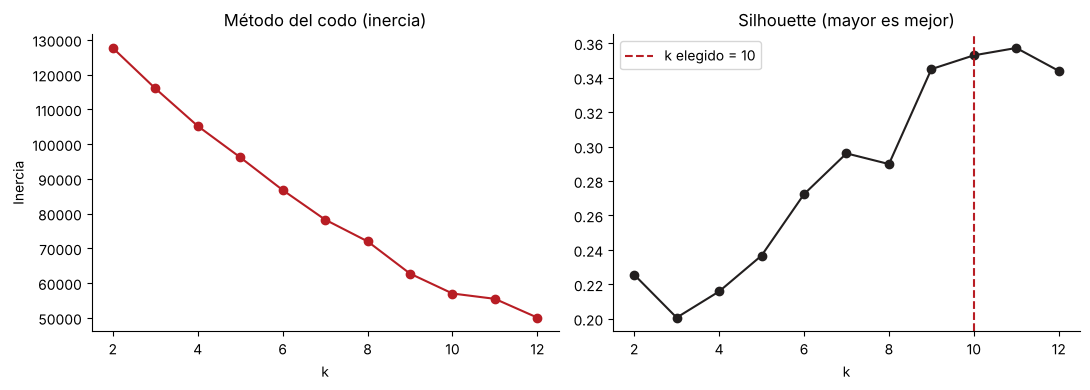

In [3]:
evaluacion = modelo.evaluarK(2, 12); display(evaluacion.round(3))
modelo.entrenar(); print('k elegido:', modelo.k, '(el menor k a 0,01 del silhouette máximo)')
modelo.guardarGraficaK('kmeans_eleccion_k.png', mostrar=True)

El silhouette sube hasta k ≈ 10–11 y luego se estabiliza. Se toma el **menor k a 0,01 del máximo**: así se evitan grupos de más (con k = 11 aparece un grupo de solo 106 títulos). El codo de la inercia no marca un quiebre claro, por eso se apoya en el silhouette.

## 3. Perfil de cada grupo

In [4]:
perfiles = modelo.perfiles()
display(perfiles[['nombre', 'titulos', 'porcentaje', 'pct_series', 'anio_medio', 'minutos_peliculas', 'temporadas_series', 'pct_infantil', 'pct_adulto']].round(1))

,nombre,titulos,porcentaje,pct_series,anio_medio,minutos_peliculas,temporadas_series,pct_infantil,pct_adulto
grupo,,,,,,,,,
1,Series · TV Dramas · adulto,657,7.5,100.0,2017.0,NaN,1.8,0.9,55.7
2,Películas · Documentaries · general,855,9.7,0.0,2015.2,87.0,NaN,5.1,40.7
3,Series · International TV Shows · general,1446,16.4,98.0,2016.4,35.0,1.6,26.2,34.3
4,Películas · International Movies · adulto,2023,23.0,0.0,2012.7,101.0,NaN,1.0,53.5
5,Películas · Thrillers · adulto,596,6.8,3.5,2014.8,103.0,1.8,0.0,68.6
6,Series · TV Comedies · general,581,6.6,100.0,2016.5,NaN,2.2,18.9,46.3
7,Películas · Action & Adventure · adulto,768,8.7,0.0,2009.3,109.0,NaN,0.1,50.1
8,Películas · Independent Movies · adulto,671,7.6,0.0,2014.4,99.0,NaN,0.4,70.2
9,Películas · Children & Family Movies · infanti...,621,7.1,0.0,2013.8,86.0,NaN,53.3,0.2


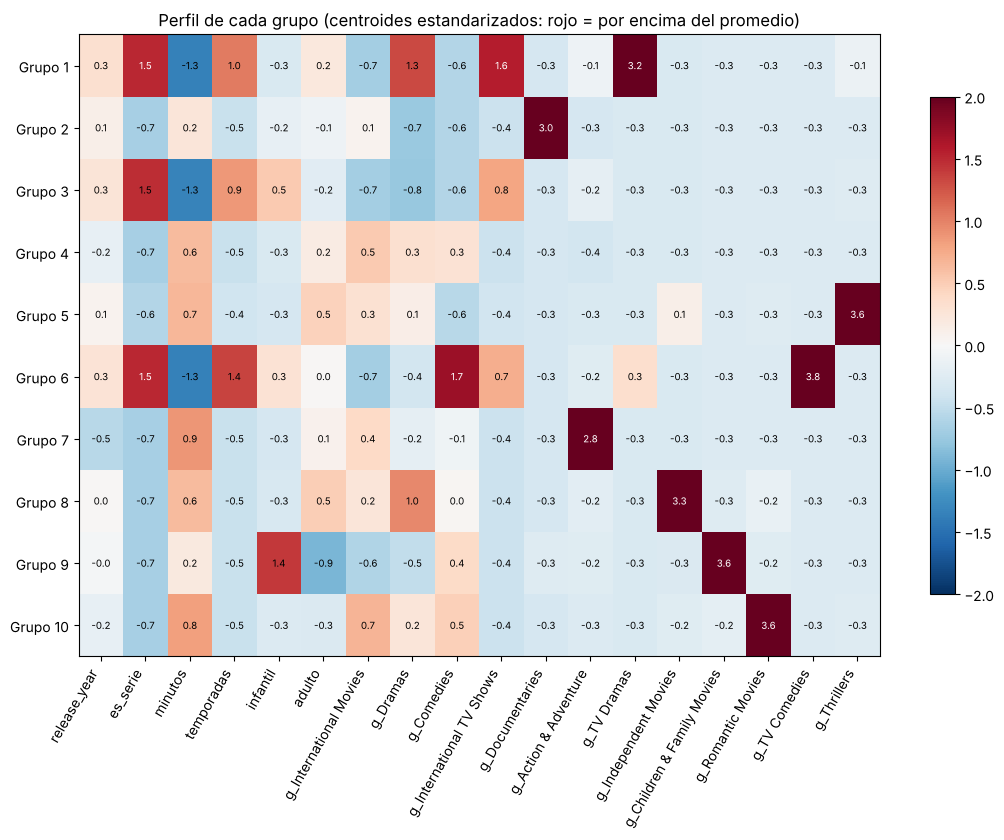

In [5]:
modelo.guardarGraficaCentroides('kmeans_centroides.png', mostrar=True)

**Cómo leer el mapa de calor.** Cada fila es un grupo y cada columna una variable estandarizada: rojo = el grupo está por encima del promedio del catálogo, azul = por debajo. Los grupos quedan definidos sobre todo por el **género** (documentales, thrillers, películas infantiles, etc.) y por el **tipo** (los grupos 1, 3 y 6 son series).

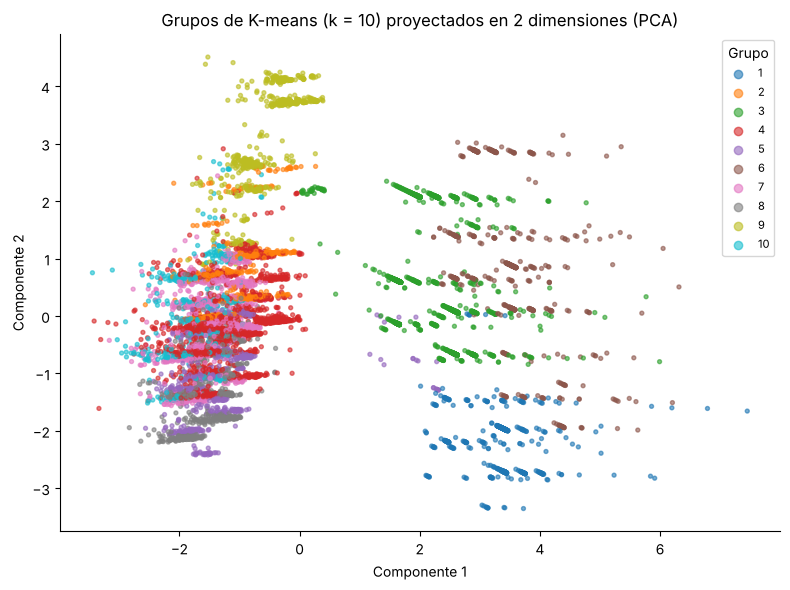

In [6]:
modelo.guardarGraficaGrupos('kmeans_grupos.png', mostrar=True)

La proyección en 2 dimensiones (PCA) resume 18 variables en dos ejes, por eso los grupos se ven parcialmente encimados: es una vista aproximada, no una prueba de separación.

## 4. ¿Se valoran distinto los grupos?

In [7]:
vg = modelo.valoracionPorGrupo(valoraciones); display(vg.round(1))
m = valoraciones.dropna(subset=['user_rating_score']).merge(modelo.titulos[['title', 'grupo']].drop_duplicates('title'), on='title')
grandes = vg[vg.titulos >= 10].index
H, p = stats.kruskal(*[m[m.grupo == g].user_rating_score for g in grandes])
print(f'Kruskal-Wallis entre los grupos con 10 o más títulos valorados {list(grandes)}: p = {p:.3f}')

,titulos,promedio,mediana,confiable
grupo,,,,
1,47,86.1,88.0,True
2,1,84.0,84.0,False
3,29,83.6,88.0,True
4,6,84.3,84.0,True
5,1,77.0,77.0,False
6,32,82.2,86.5,True
7,1,84.0,84.0,False
8,2,75.0,75.0,False
9,16,80.7,82.0,True


Kruskal-Wallis entre los grupos con 10 o más títulos valorados [1, 3, 6, 9]: p = 0.424


## 5. Conclusión
- **K-means con k = 10** segmenta el catálogo en grupos interpretables: por ejemplo series de drama para adultos (grupo 1), documentales (grupo 2), series internacionales (grupo 3), películas internacionales para adultos (grupo 4, el más grande con 23 % del catálogo) y películas infantiles y familiares (grupo 9).
- **La estructura es débil:** el silhouette es 0.35, por debajo de 0,5. Los grupos son **segmentos descriptivos** útiles para resumir el catálogo, no categorías naturales con fronteras nítidas.
- **Valoración por grupo:** solo 5 grupos tienen 5 o más títulos valorados (el resto tiene 1 o 2 y no se puede interpretar). Entre los que tienen 10 o más: grupo 1 (86.1, n = 47), grupo 3 (83.6, n = 29), grupo 6 (82.2, n = 32), grupo 9 (80.7, n = 16). Las series de drama para adultos se valoran más y las películas infantiles y familiares menos, lo que coincide con el árbol y con el análisis de audiencia. Sin embargo, la diferencia entre estos grupos NO es estadísticamente significativa (Kruskal-Wallis, p = 0.424), así que hay que presentarla como una tendencia.
- **Escalamiento:** aquí sí se aplicó `StandardScaler`, porque K-means mide distancias; es el contraste con el árbol y Naive Bayes, donde escalar no cambia nada.